# pipeline for finding distance of intercellular transcripts to nuclei and mapping their distribution by distance
this assumes a null hypothesis that a given transcript is evenly distributed across the area of all cells in a z plane (might update this later)

In [1]:
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
from sklearn.neighbors import KernelDensity
from sklearn.model_selection import GridSearchCV, KFold
from KDEpy import FFTKDE
from matplotlib import cm
import geopandas as gpd
import matplotlib as plt
from importlib import reload 
import pickle as pkl
import area_corrected_kde as ack
import multi_dataset_kde as mdk

dpath = "luca-data/luca-filtered/"  #where the input files are stored
odir = "ndp-output/"                 #directory to save files to
dist_cut = 5                         #the distance over which the AUC of the KDES will sum to 1 (in um)
zplanes = [2, 3, 4, 5, 6]            #from dft.z_plane.unique()

In [3]:
#load data
#metadata
meta1  = pd.read_csv(dpath+"TACB_cell_meta.csv")
meta1["cell_id"] = meta1["cell_id"].astype(str) #convert from float to str
cell_id_keep = meta1[meta1["CM_gt500um3"]==True]["cell_id"].to_list()
meta = meta1[meta1['cell_id'].isin(cell_id_keep)]

#transcripts
dft1 = pd.read_parquet(dpath+"TACB_barcodes.parquet")
#dftin1 = dft[['cell_id','gene','x','y']]
dft1.rename(columns = {'gene':'name'},inplace=True) #i should fix this to give an input column name for gene name
dft = dft1[dft1['cell_id'].isin(cell_id_keep)]


#cell boundaries
cellb1 = gpd.read_parquet(dpath+"TACB_cell_boundaries.parquet")
cellb = cellb1[cellb1['cell_id'].isin(cell_id_keep)]

#nuclei boundaries
with open("luca-data/TACB_nuc_to_cell.pkl", 'rb') as file: #map nuclei ids to cell ids
    n2c = pkl.load(file)
nuc1   = gpd.read_parquet(dpath+"TACB_nuclei_boundaries.parquet")
nuc1["cell_id"] = nuc1["nuc_id"].map(n2c)
nuc = nuc1[nuc1['cell_id'].isin(cell_id_keep)]

#i am storing the original files with all the cells with the 1 suffix. dont need to do this if you are worried about memory

In [ ]:
def getDistanceByZ(meta,dft,cellb,nuc,odir=odir,z=None):
    zl = z
    if z is None:
        zl = cellb["z_plane"].unique().tolist()
    elif type(z) is not list:
        zl = list(z)
    for z in zl:
        print(z)
        metac   = meta[meta["z_planes"].str.contains(str(z))] #only find cells that are in the z plane
        dftc = dft[dft['z_plane']==z]
        cellbc = cellb[cellb['z_plane']==z]
        nucc = nuc[nuc['z_plane']==z]
        dfc, signed_distancec = ack.add_signed_distance(dftc, nucc, label_col='cell_id')
        dfc.to_parquet(odir+"TACB-z"+str(z)+"-transcripts-w-distance.parquet")
        regionsc = dict(zip(cellbc['cell_id'], cellbc.geometry))
        ref_dc = ack.make_reference_distances(signed_distancec, bounds=regionsc)
        np.save(odir+"TACB-z"+str(z)+"-reference-null.npy", ref_dc)
getDistanceByZ(meta,dft,cellb,nuc) #took a little over a minute to run

2


/media/volume/volume_spatial/aidan/scripts/new-kde/area_corrected_kde.py:94: UserWarning: 19371 labels have no (non-empty) shapes; their points get NaN: ['3291.0', '3803.0', '3402.0', '1290.0', '3672.0', '3364.0', '3061.0', '3330.0', '3332.0', '3754.0'] ...
  warnings.warn(
/media/volume/volume_spatial/aidan/scripts/new-kde/area_corrected_kde.py:94: UserWarning: 18607 labels have no (non-empty) shapes; their points get NaN: ['1290.0', '3061.0', '3159.0', '3182.0', '3211.0', '3291.0', '3330.0', '3332.0', '3364.0', '3402.0'] ...
  warnings.warn(
/media/volume/volume_spatial/aidan/scripts/new-kde/area_corrected_kde.py:206: UserWarning: Dropping 604,190 reference points with no distance (labels without shapes).
  warnings.warn(f"Dropping {bad.sum():,} reference points with no "


3


/media/volume/volume_spatial/aidan/scripts/new-kde/area_corrected_kde.py:94: UserWarning: 19342 labels have no (non-empty) shapes; their points get NaN: ['3291.0', '3803.0', '3736.0', '3402.0', '3672.0', '1290.0', '3364.0', '3182.0', '3061.0', '3330.0'] ...
  warnings.warn(
/media/volume/volume_spatial/aidan/scripts/new-kde/area_corrected_kde.py:94: UserWarning: 18884 labels have no (non-empty) shapes; their points get NaN: ['1290.0', '3061.0', '3159.0', '3182.0', '3211.0', '3291.0', '3330.0', '3332.0', '3364.0', '3402.0'] ...
  warnings.warn(
/media/volume/volume_spatial/aidan/scripts/new-kde/area_corrected_kde.py:206: UserWarning: Dropping 599,097 reference points with no distance (labels without shapes).
  warnings.warn(f"Dropping {bad.sum():,} reference points with no "


4


/media/volume/volume_spatial/aidan/scripts/new-kde/area_corrected_kde.py:94: UserWarning: 19357 labels have no (non-empty) shapes; their points get NaN: ['3291.0', '3803.0', '3736.0', '3672.0', '1290.0', '3402.0', '3364.0', '3061.0', '3182.0', '3330.0'] ...
  warnings.warn(
/media/volume/volume_spatial/aidan/scripts/new-kde/area_corrected_kde.py:94: UserWarning: 18857 labels have no (non-empty) shapes; their points get NaN: ['1290.0', '3061.0', '3159.0', '3182.0', '3211.0', '3291.0', '3330.0', '3332.0', '3364.0', '3402.0'] ...
  warnings.warn(
/media/volume/volume_spatial/aidan/scripts/new-kde/area_corrected_kde.py:206: UserWarning: Dropping 603,879 reference points with no distance (labels without shapes).
  warnings.warn(f"Dropping {bad.sum():,} reference points with no "


5


/media/volume/volume_spatial/aidan/scripts/new-kde/area_corrected_kde.py:94: UserWarning: 19497 labels have no (non-empty) shapes; their points get NaN: ['3291.0', '3803.0', '3736.0', '3402.0', '1290.0', '3364.0', '3672.0', '3159.0', '3061.0', '3330.0'] ...
  warnings.warn(
/media/volume/volume_spatial/aidan/scripts/new-kde/area_corrected_kde.py:94: UserWarning: 18990 labels have no (non-empty) shapes; their points get NaN: ['1290.0', '3061.0', '3159.0', '3182.0', '3211.0', '3291.0', '3330.0', '3332.0', '3364.0', '3402.0'] ...
  warnings.warn(
/media/volume/volume_spatial/aidan/scripts/new-kde/area_corrected_kde.py:206: UserWarning: Dropping 615,733 reference points with no distance (labels without shapes).
  warnings.warn(f"Dropping {bad.sum():,} reference points with no "


6


/media/volume/volume_spatial/aidan/scripts/new-kde/area_corrected_kde.py:94: UserWarning: 19606 labels have no (non-empty) shapes; their points get NaN: ['3291.0', '3803.0', '3964.0', '3736.0', '3402.0', '3672.0', '1290.0', '3364.0', '3806.0', '3211.0'] ...
  warnings.warn(
/media/volume/volume_spatial/aidan/scripts/new-kde/area_corrected_kde.py:94: UserWarning: 19128 labels have no (non-empty) shapes; their points get NaN: ['1290.0', '3159.0', '3182.0', '3211.0', '3291.0', '3330.0', '3332.0', '3364.0', '3402.0', '3672.0'] ...
  warnings.warn(
/media/volume/volume_spatial/aidan/scripts/new-kde/area_corrected_kde.py:206: UserWarning: Dropping 621,973 reference points with no distance (labels without shapes).
  warnings.warn(f"Dropping {bad.sum():,} reference points with no "


#### start from here if you dont want to generate distances

In [ ]:
#this one loads from individual files per z plane
datasets = {z: (pd.read_parquet(odir+"TACB-z"+str(z)+"-transcripts-w-distance.parquet"),np.load(odir+"TACB-z"+str(z)+"-reference-null.npy")) for z in zplanes} #for z in dft["z_plane"].unique().tolist()
#this one is a few seconds faster i think

In [8]:
#this one loads from one transcript file
fulldfwithdistance = pd.read_parquet(odir+"TACB-ALL-transcripts-w-distance.parquet")
datasets = {z: (fulldfwithdistance[fulldfwithdistance["z_plane"]==z],np.load(odir+"TACB-z"+str(z)+"-reference-null.npy")) for z in zplanes} #for z in dft["z_plane"].unique().tolist()

In [ ]:
#saves all the distances as one file
#fulldfwithdistance = pd.concat([datasets[z][0] for z in datasets.keys()])
#fulldfwithdistance.to_parquet(odir+"TACB-ALL-transcripts-w-distance.parquet")

In [9]:
names, grid, rho, ref, bw, dens, per_ds = mdk.area_corrected_kdes_multi(datasets, T=dist_cut)

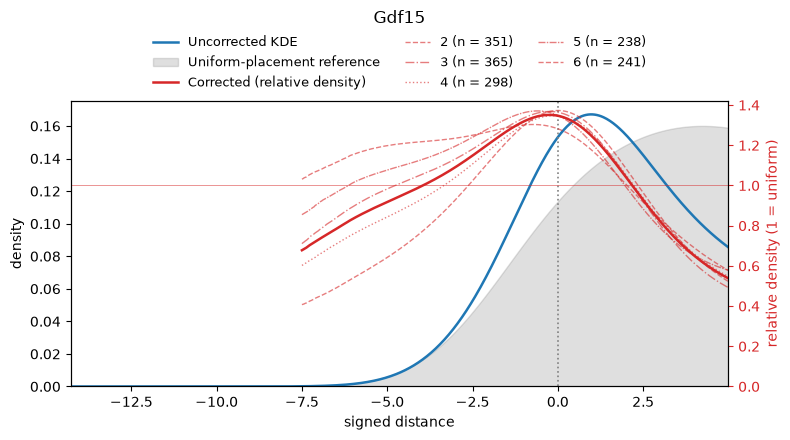

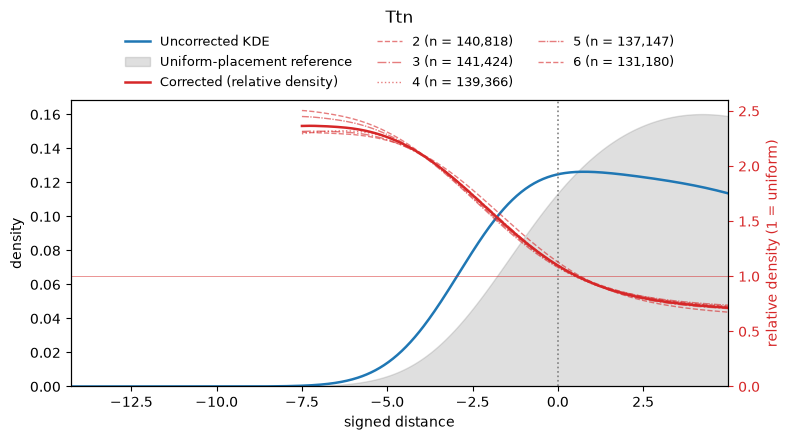

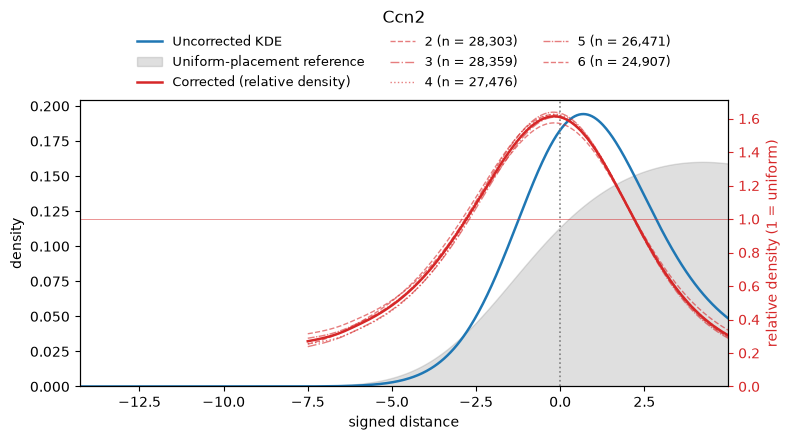

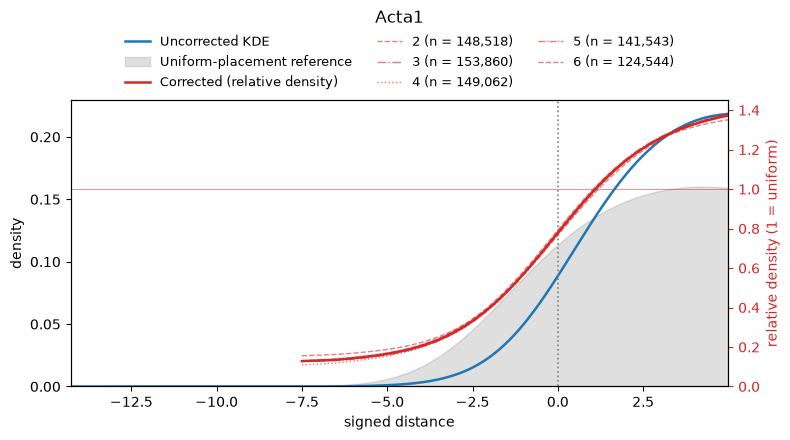

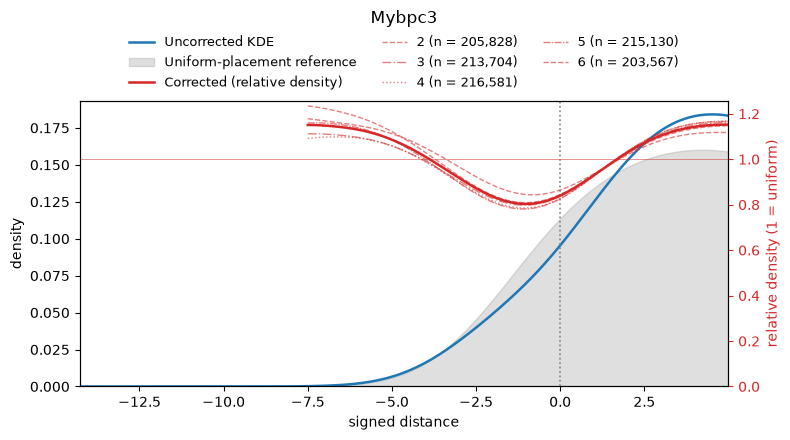

In [10]:
for gene in ['Gdf15', 'Ttn','Ccn2','Acta1','Mybpc3']:
    mdk.plot_gene_multi(gene, names, grid, rho, dens, per_ds)

(<Figure size 1200x1200 with 12 Axes>,
 array([[<Axes: title={'center': 'Cluster 1  (n = 27)'}, ylabel='relative density'>,
         <Axes: title={'center': 'Cluster 2  (n = 19)'}>,
         <Axes: title={'center': 'Cluster 3  (n = 15)'}>],
        [<Axes: title={'center': 'Cluster 4  (n = 12)'}, ylabel='relative density'>,
         <Axes: title={'center': 'Cluster 5  (n = 10)'}>,
         <Axes: title={'center': 'Cluster 6  (n = 6)'}>],
        [<Axes: title={'center': 'Cluster 7  (n = 5)'}, ylabel='relative density'>,
         <Axes: title={'center': 'Cluster 8  (n = 5)'}>,
         <Axes: title={'center': 'Cluster 9  (n = 3)'}>],
        [<Axes: title={'center': 'Cluster 10  (n = 3)'}, xlabel='signed distance', ylabel='relative density'>,
         <Axes: title={'center': 'Cluster 11  (n = 3)'}, xlabel='signed distance'>,
         <Axes: title={'center': 'Unassigned  (n = 3)'}, xlabel='signed distance'>]],
       dtype=object))

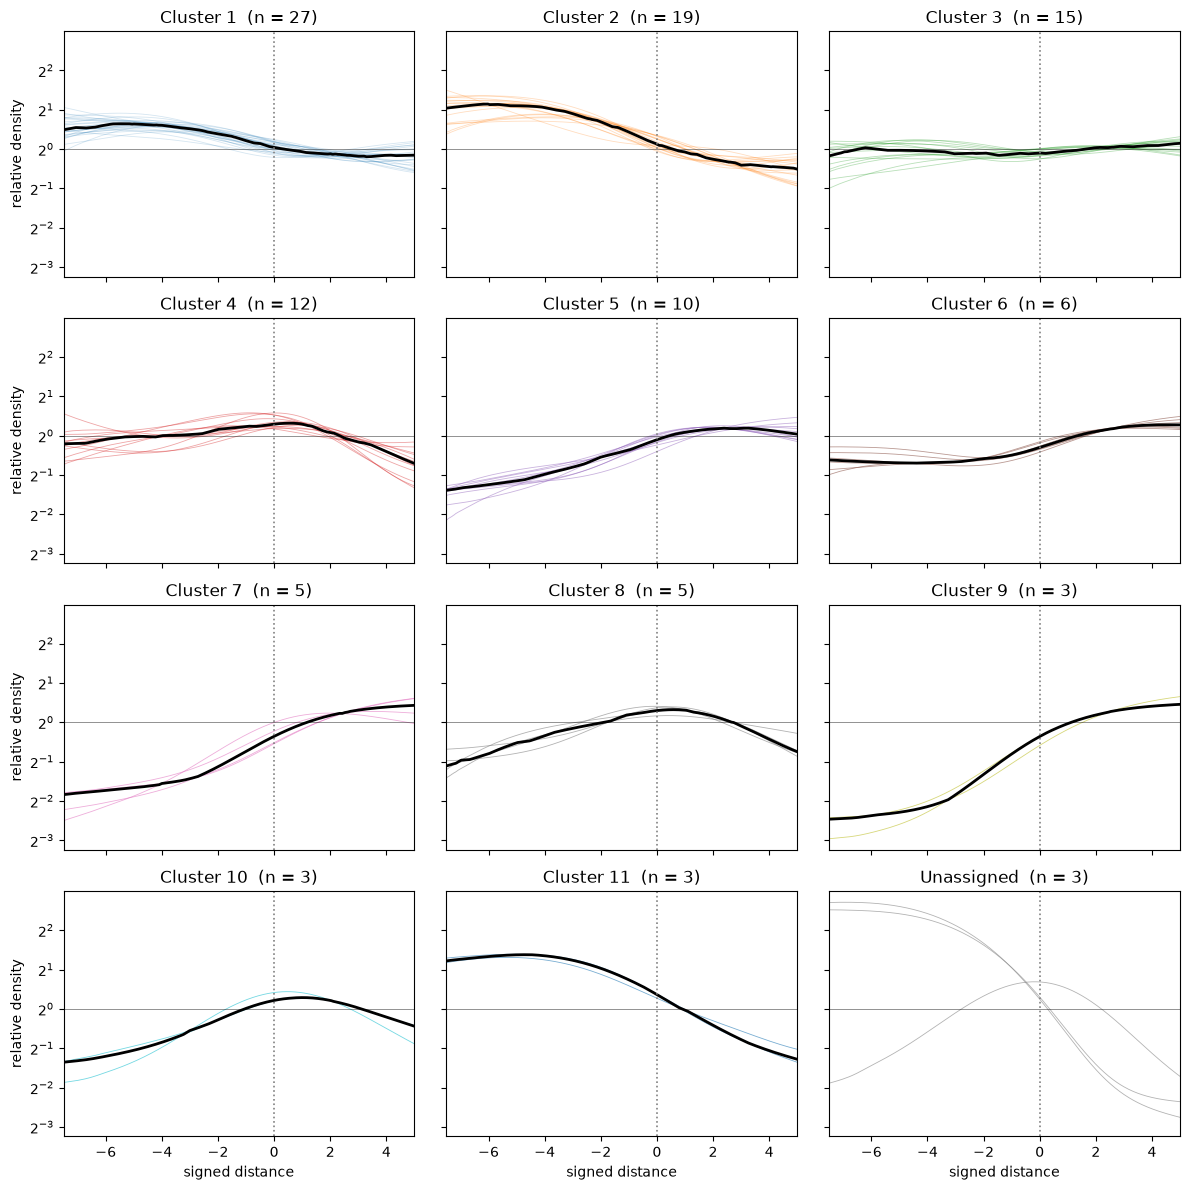

In [7]:
counts = per_ds['n'].sum(axis=1)
labels, Z, scores = ack.cluster_genes(names, rho, ref, max_dist=0.5, counts=counts, min_count=200, weight = 'uniform')
ack.plot_cluster_profiles(labels, names, grid, rho)

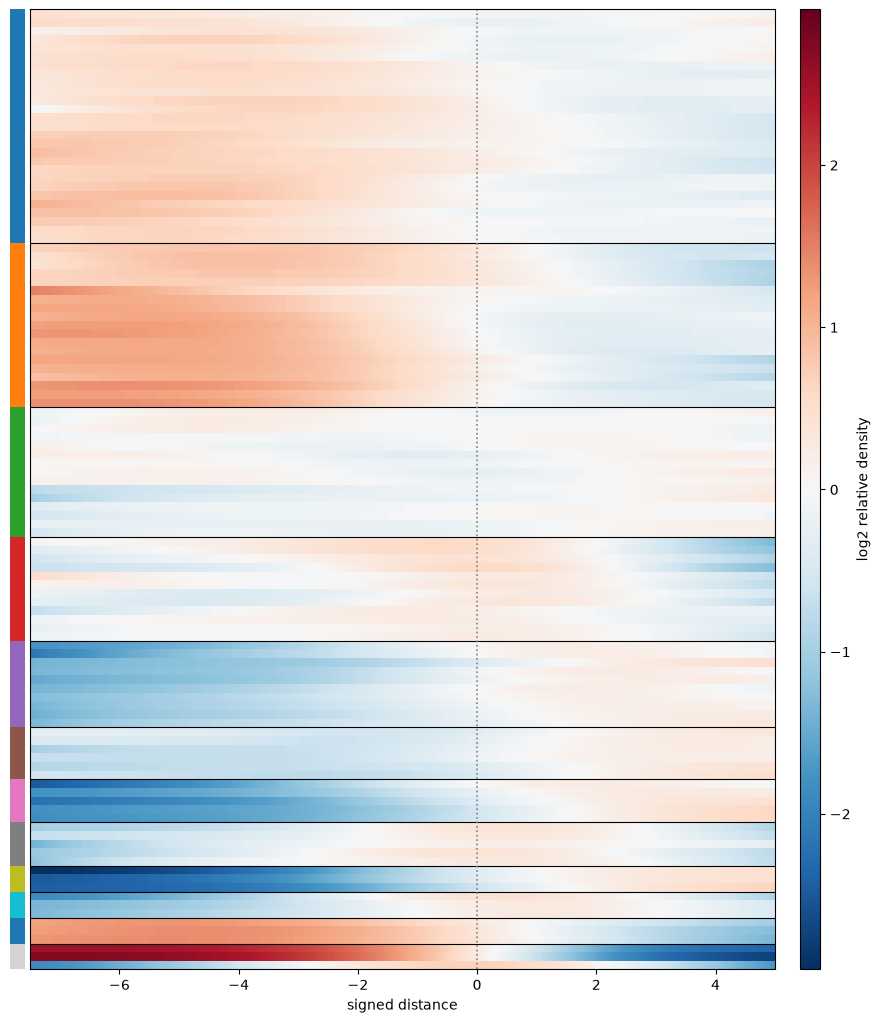

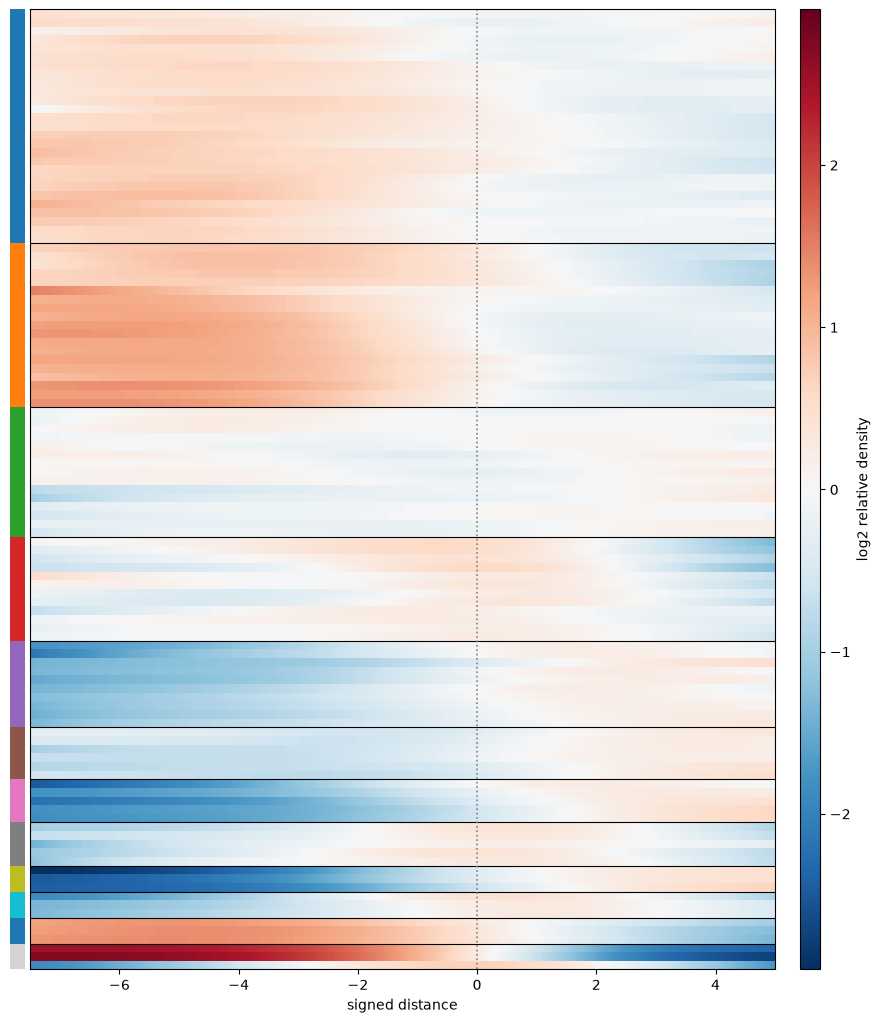

In [35]:
ack.plot_cluster_heatmap(labels, Z, names, grid, rho)

(<Figure size 800x420 with 1 Axes>, <Axes: xlabel='signed distance'>)

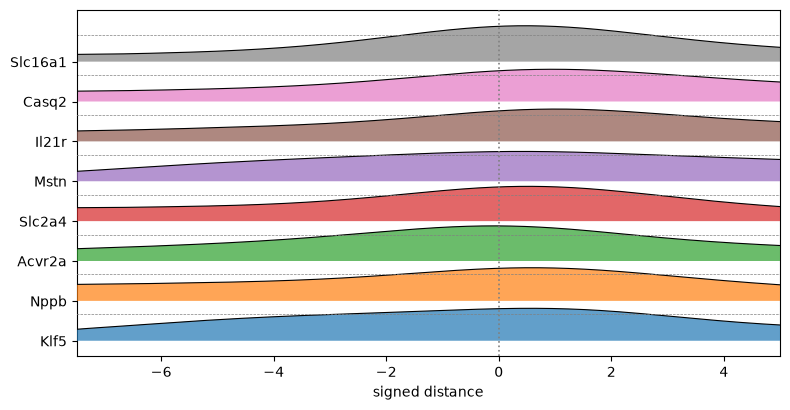

In [31]:
ack.plot_ridgeline(names, grid, rho, genes=labels[labels.isin([8,10])].index)

(<Figure size 800x600 with 1 Axes>,
 <Axes: xlabel='log2 enrichment, outside vs inside\n(< 0 favours inside,  > 0 favours outside)', ylabel='number of points (d ≤ T)'>)

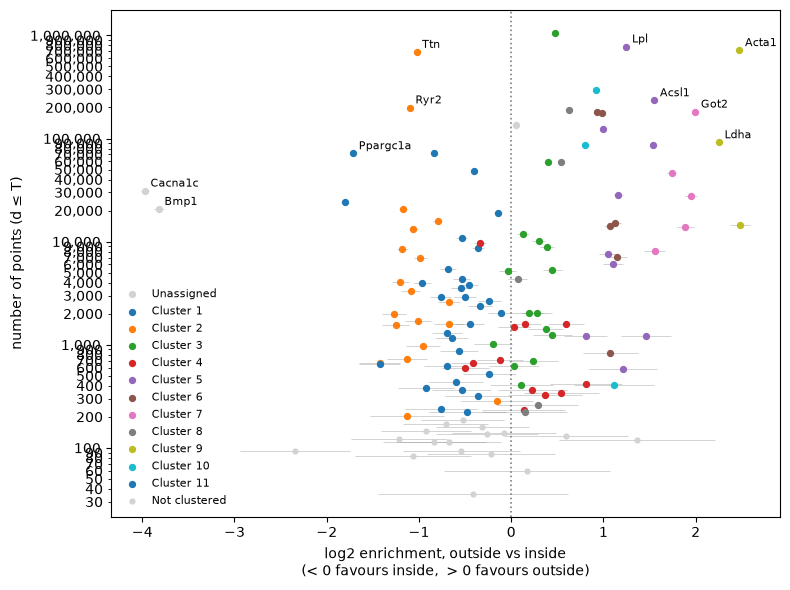

In [34]:
#Inside vs outside the nucleus, pooled
io = mdk.inside_outside_enrichment_multi(datasets, T=dist_cut)

ack.plot_inside_outside(io, labels=labels)
#mdk.plot_inside_vs_outside_multi(io, labels=labels)